# Load packages

In [1]:
import pandas as pd
import geopandas as gpd

import json
from pathlib import Path
from tqdm import tqdm

# Read data

## Read Flickr data

In [2]:
# Read the geopackage
gdf_flickr = gpd.read_file('../../../data/Flickr/flickr_finland_state_lands.gpkg')

# Convert date_taken to datetime and extract year, month, and date
gdf_flickr['date_taken'] = pd.to_datetime(gdf_flickr['date_taken'], unit='s')

gdf_flickr['year'] = gdf_flickr['date_taken'].dt.year
gdf_flickr['month'] = gdf_flickr['date_taken'].dt.month
gdf_flickr['date'] = gdf_flickr['date_taken'].dt.date

gdf_flickr = gdf_flickr[gdf_flickr['year']>=2018]

gdf_flickr.shape

(15471, 19)

In [3]:
# Save the csv and geopackage file
# gdf_flickr.to_csv("../../../data/Flickr/flickr_finland_state_lands.csv", index=False)
# gdf_flickr.to_file("../../../data/Flickr/flickr_finland_state_lands.gpkg", driver="GPKG", layer="filtered_flickr_points")

# Read saved data
# df_flickr = pd.read_csv("../../../data/Flickr/flickr_finland_state_lands.csv", index=False)
gdf_flickr = gpd.read_file("../../../data/Flickr/flickr_finland_state_lands.gpkg")
gdf_flickr.shape

(16773, 18)

## Read boundaries

In [4]:
# Read Finland boundary shapefile
gdf_finland = gpd.read_file('../../../data/boundaries/Finland_shapefile/Finland_boundaries.shp')
gdf_finland.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [5]:
# Read state-owned lands boundary
gdf_state_lands = gpd.read_file('../../../data/boundaries/MH kiinteistot.gpkg')
gdf_state_lands.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [6]:
# Read state-owned nature reserves boundary
gdf_state_nature_reserves = gpd.read_file('../../../data/boundaries/luonnonsuojelualueet_valtio/LsAlueValtio.shp')
gdf_state_nature_reserves.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [7]:
# Read national parks boundary
gdf_national_parks = gpd.read_file('../../../data/boundaries/finnish_national_parks_syke_2024.gpkg')
gdf_national_parks.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [8]:
# Read wilderness areas boundary
gdf_wilderness = gpd.read_file('../../../data/boundaries/luonnonsuojelualueet_eramaa/LsAlueEramaa.shp')
gdf_wilderness.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

# Clean activities

## Read LLM inferenced information from JSON files 

In [4]:
# Folder containing LLM inferenced information JSON files
json_folder = Path("../../../data/Flickr/inference_json_output")

json_files = list(json_folder.glob("*.json"))

rows = []

for file in tqdm(json_files, desc="Processing JSON files"):

    try:
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)

        image_id = data.get("image_id")

        base_row = {
            "image_id": image_id,
            "human_presence": data.get("human_presence"),
            "accompany_type": data.get("accompany_type", "").strip(),
            "age_group": data.get("age_group", "").strip(),
            "gender": data.get("gender", "").strip(),
        }

        activities = data.get("activities", [])

        # keep rows even without activities
        if not activities:
            rows.append({
                **base_row,
                "activity": None,
                "type": None
            })

        else:
            for activity in activities:

                activity_name = activity.get("name", "").strip()

                if activity_name:
                    activity_name = (
                        activity_name[:1].upper() +
                        activity_name[1:].lower()
                    )

                rows.append({
                    **base_row,
                    "activity": activity_name,
                    "type": activity.get("type", "").strip()
                })

    except Exception as e:
        print(f"\nError reading {file.name}: {e}")

df_inferenced = (
    pd.DataFrame(rows)
    .drop_duplicates(ignore_index=True)
)

df_inferenced.to_csv('../../../data/Flickr/Flickr_inferenced.csv', index=False)

print(df_inferenced.shape)

Processing JSON files: 0it [00:00, ?it/s]

(0, 0)


In [12]:
df_inferenced = pd.read_csv('../../../data/Flickr/Flickr_inferenced.csv')
df_inferenced = df_inferenced[~df_inferenced['activity'].isna()]
df_inferenced.shape

(1775, 7)

In [13]:
df_inferenced

,image_id,human_presence,accompany_type,age_group,gender,activity,type
13,48104010326,1,Unknown,Unknown,Unknown,"Forestry work such as planting, nursery manage...",survey_activity
14,48032028188,1,Unknown,Unknown,Unknown,Diving,survey_activity
15,48032028188,1,Unknown,Unknown,Unknown,Scuba diving,survey_activity
16,48032028188,1,Unknown,Unknown,Unknown,Underwater photography,new_activity
18,49538232706,1,Unknown,Unknown,Unknown,Mountain biking,survey_activity
...,...,...,...,...,...,...,...
17021,50628547668,1,Unknown,Unknown,Unknown,Boating,survey_activity
17031,51049875966,1,Unknown,Unknown,Unknown,Cycling,survey_activity
17050,51881493691,1,Unknown,Unknown,Unknown,Snowshoeing,survey_activity
17051,51881493691,1,Unknown,Unknown,Unknown,Ice fishing,survey_activity


## Read LVVI3 activities for postprocessing

In [8]:
# Get LVVI3 survey activities and new activities discovered from YouTube data for postprocessing 
df_activities_post_origin = pd.read_csv('../../../data/LVVI3/LVVI3_activities_inference_postprocessing.csv')
df_activities_post = df_activities_post_origin[df_activities_post_origin['type']=='survey_activity']
ls_activities_post = df_activities_post['activity'].unique().tolist()
ls_subactivities_post = df_activities_post['sub_activity'].unique().tolist()
ls_activities_post = list(set(ls_activities_post + ls_subactivities_post))
print(ls_activities_post)

['Kayaking', 'Backcountry skiing', 'Other nature observation', 'Nordic walking', 'Bird hunting', 'Snorkelling', 'Frisbee golf', 'Small game hunting', 'Water sports', 'Skiing', 'Skating', 'Nature product collection', 'Cross-country skiing', 'Flying a kite', 'Keeping livestock in a natural environment in leisure time', 'Management of meadows or other natural habitats', 'Fuelwood procurement, collection of twigs, branches and trees for domestic use', 'Worm fishing', 'Walking', 'Snowboarding', 'Canoeing', 'Sledding', 'Swimming', 'Mountain biking', 'Flying a drone', 'Fly fishing', 'Painting', 'Free guided excursion', 'Sailing small boat', 'Outdoor activities with children', 'Scout excursion', 'Travelling or staying in a caravan or camper', 'Downhill skiing', 'Motorboat small boat', 'Guided excursion for a fee', 'Boating', 'Orienteering', 'Guided tour', 'Camping', 'Kicksledding', 'Crabbing', 'Trolling', 'Hunting', 'Fishing with long line, hook etc.', 'Golf', 'Growing ornamental plants, veget

## Match with activities for postprocessing

In [9]:
# Get activities inferenced by LLM from Flickr data
ls_activities_inferenced = df_inferenced.activity.unique().tolist()

In [10]:
ls_activities_missing = [act for act in ls_activities_inferenced if act not in ls_activities_post]
len(ls_activities_missing)

49

In [11]:
non_activities =[
    'Burnout', 'Campfire', 'Airshow', 'Köydenheitto',
    'Tarpoja', 'Solmumestari', 'Day trip', 'Tastings',
    'Backpacking', 'Dancing', 'Cooking with fire',
    'Cooking', 'Knot tying', 
]

df_inferenced = df_inferenced[~df_inferenced["activity"].isin(non_activities)]

In [12]:
# Rename inferenced activities to match with the LVVI3 activity list
df_inferenced["activity"] = df_inferenced["activity"].replace("Underwater photography", "Nature photography")
df_inferenced["activity"] = df_inferenced["activity"].replace("Gravel bicycling", "Cycling")
df_inferenced["activity"] = df_inferenced["activity"].replace("Flying a kite, drone or drone", "Flying a drone")
df_inferenced["activity"] = df_inferenced["activity"].replace("Paddling", "Boating")
df_inferenced["activity"] = df_inferenced["activity"].replace("Birding", "Bird watching")
df_inferenced["activity"] = df_inferenced["activity"].replace("Winter hiking", "Hiking")
df_inferenced["activity"] = df_inferenced["activity"].replace("Mountain climbing", "Climbing")
df_inferenced["activity"] = df_inferenced["activity"].replace("Hike", "Hiking")
df_inferenced["activity"] = df_inferenced["activity"].replace("Fat biking", "Cycling")
df_inferenced["activity"] = df_inferenced["activity"].replace("Vaellus", "Hiking")
df_inferenced["activity"] = df_inferenced["activity"].replace("Sailing", "Boating")
df_inferenced["activity"] = df_inferenced["activity"].replace("Picnics", "Picnicking")
df_inferenced["activity"] = df_inferenced["activity"].replace("Drone flying", "Flying a drone")
df_inferenced["activity"] = df_inferenced["activity"].replace("Winter walking", "Hiking")
df_inferenced["activity"] = df_inferenced["activity"].replace("Trekking", "Hiking")
df_inferenced["activity"] = df_inferenced["activity"].replace("Rafting", "Boating")
df_inferenced["activity"] = df_inferenced["activity"].replace("Sunbathing or lounging elsewhere in nature", "Sunbathing")
df_inferenced["activity"] = df_inferenced["activity"].replace("Watchingsunset", "Nature observation")
df_inferenced["activity"] = df_inferenced["activity"].replace("Randonee walking", "Hiking")
df_inferenced["activity"] = df_inferenced["activity"].replace("Sunbathing, lounging or sightseeing on the beach", "Sunbathing")
df_inferenced["activity"] = df_inferenced["activity"].replace("Hunter skiing", "Skiing")
df_inferenced["activity"] = df_inferenced["activity"].replace("Biking", "Cycling")
df_inferenced["activity"] = df_inferenced["activity"].replace("Stargazing", "Nature observation")
df_inferenced["activity"] = df_inferenced["activity"].replace("Snow walk", "Walking")


In [13]:
# Update activity type to new_activity for those are not in the LVVI3 activity list
df_inferenced["activity"] = df_inferenced["activity"].replace("Grill", "Grilling")
df_inferenced.loc[df_inferenced["activity"] == "Grilling", "type"] = "new_activity"

df_inferenced.loc[df_inferenced["activity"] == "Rallying", "type"] = "new_activity"
df_inferenced.loc[df_inferenced["activity"] == "Ice fishing", "type"] = "new_activity"
df_inferenced.loc[df_inferenced["activity"] == "Yoga", "type"] = "new_activity"
df_inferenced.loc[df_inferenced["activity"] == "Archery", "type"] = "new_activity"
df_inferenced.loc[df_inferenced["activity"] == "Glider flying", "type"] = "new_activity"

In [14]:
# Rename activities and label those relevant to LVVI3 activities as survey_activity
df_inferenced["activity"] = df_inferenced["activity"].replace("Dog sledding", "Husky safari")
df_inferenced.loc[df_inferenced["activity"] == "Husky safari", "type"] = "new_activity"

df_inferenced.loc[df_inferenced["activity"] == "Ice climbing", "type"] = "new_activity"

df_inferenced["activity"] = df_inferenced["activity"].replace("Northern lights viewing", "Northern lights watching")
df_inferenced.loc[df_inferenced["activity"] == "Northern lights watching", "type"] = "new_activity"

df_inferenced.loc[df_inferenced["activity"] == "Reindeer racing", "type"] = "new_activity"

df_inferenced["activity"] = df_inferenced["activity"].replace("Glide", "Glider flying")
df_inferenced.loc[df_inferenced["activity"] == "Glider flying", "type"] = "new_activity"

df_inferenced["activity"] = df_inferenced["activity"].replace("Reindeer herding", "Reindeer safari")
df_inferenced.loc[df_inferenced["activity"] == "Reindeer safari", "type"] = "new_activity"

In [15]:
df_activities_survey = df_inferenced[df_inferenced['type'] == 'survey_activity']
ls_activities_survey = df_activities_survey['activity'].unique().tolist()
ls_activities_survey_not_matching = [activity for activity in ls_activities_survey if activity not in ls_activities_post]
len(ls_activities_survey_not_matching)

0

In [16]:
df_activities_new = df_inferenced[df_inferenced['type'] == 'new_activity']
ls_activities_new = df_activities_new['activity'].unique().tolist()
ls_activities_new_matching = [activity for activity in ls_activities_new if activity in ls_activities_post]
# Update activity type to survey_activity for those are in the LVVI3 activity list
for act in ls_activities_new_matching:
    df_inferenced.loc[df_inferenced["activity"] == act, "type"] = "survey_activity"

In [17]:
df_activities_new = df_inferenced[df_inferenced['type'] == 'new_activity']
ls_activities_new = df_activities_new['activity'].unique().tolist()
len(ls_activities_new)

11

In [18]:
ls_activities_new

['Grilling',
 'Rallying',
 'Husky safari',
 'Ice climbing',
 'Yoga',
 'Ice fishing',
 'Northern lights watching',
 'Reindeer racing',
 'Glider flying',
 'Reindeer safari',
 'Archery']

## Map sub_activities to activities

In [19]:
# Create a mapping: sub_activity → activity
sub_to_activity = df_activities_post_origin.set_index('sub_activity')['activity'].to_dict()

# Rename the activity column to sub_activity
df_inferenced = df_inferenced.rename(columns={"activity": "sub_activity"})
# Map the 'sub_activity' column to get the corresponding 'activity'
df_inferenced['activity'] = df_inferenced['sub_activity'].map(sub_to_activity)

# Update activity type
df_inferenced = df_inferenced.drop(columns=['type'])
df_inferenced = df_inferenced.merge(df_activities_post_origin[['structural_activity', 'sub_activity', 'type']], on='sub_activity', how='left')

In [20]:
df_inferenced.activity.value_counts()

activity
Cycling                                                        294
Walking                                                        286
Skiing                                                         165
Nature photography                                             155
Boating                                                        129
Diving                                                         124
Skating                                                        121
Guided tour                                                     86
Forest                                                          55
Snowmobiling                                                    38
Husky safari                                                    27
Fishing                                                         27
Climbing                                                        25
Camping                                                         23
Flying a drone                                       

In [21]:
df_inferenced.sub_activity.value_counts()

sub_activity
Hiking                  271
Mountain biking         261
Nature photography      155
Cross-country skiing    153
Snowshoeing             108
                       ... 
Reindeer racing           1
Horseback riding          1
Reindeer safari           1
Flying a kite             1
Archery                   1
Name: count, Length: 61, dtype: int64

# Clean demographics

## Read facial recognition results from JSON files

In [ ]:
# folder containing facial recognition JSON files
json_folder = Path("../../../data/Flickr/gender_age_output")

json_files = list(json_folder.glob("*.json"))

rows = []

for file in tqdm(json_files, desc="Processing face JSON files"):

    try:
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)

        image_id = data.get("image_id")

        # keep only images with detected faces
        if not data.get("has_face", False):
            continue

        faces = data.get("faces", [])

        # keep row even if faces list is empty
        if not faces:
            rows.append({
                "image_id": image_id,
                "num_faces": data.get("num_faces"),
                "face_index": None,
                "age": None,
                "gender": None,
                "gender_confidence": None,
                "face_confidence": None
            })

        else:
            for face in faces:

                rows.append({
                    "image_id": image_id,
                    "num_faces": data.get("num_faces"),
                    "face_index": face.get("face_index"),
                    "age": face.get("age"),
                    "gender": face.get("gender", "").strip(),
                    "gender_confidence": face.get("gender_confidence"),
                    "face_confidence": face.get("face_confidence")
                })

    except Exception as e:
        print(f"\nError reading {file.name}: {e}")

# create dataframe and remove duplicates
df_faces = (
    pd.DataFrame(rows)
    .drop_duplicates(ignore_index=True)
)

# save to csv
df_faces.to_csv(
    "../../../data/Flickr/Flickr_face_results.csv",
    index=False
)

print(df_faces.shape)
print(df_faces.head())

In [37]:
df_faces = pd.read_csv("../../../data/Flickr/Flickr_face_results.csv")
df_faces.shape

(290, 7)

In [38]:
# Categorize age into groups
df_faces['age_group'] = pd.cut(
    df_faces['age'],
    bins=[0, 16, 25, 35, 45, 55, 65, 75, 100],
    labels=['<16', '16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '>75'],
    right=False
)

# Rename Man and Woman as Male and Female
df_faces['gender'] = df_faces['gender'].replace({'Man': 'Male', 'Woman': 'Female'})

In [39]:
df_faces.age_group.value_counts()

age_group
25-34    104
35-44    101
45-54     73
16-24      8
55-64      4
<16        0
65-74      0
>75        0
Name: count, dtype: int64

In [40]:
df_faces.gender.value_counts()

gender
Male      223
Female     67
Name: count, dtype: int64

# Identify trips

## Activity trips

In [46]:
import pandas as pd
import geopandas as gpd

# =========================================================
# 1. PREPARE DATA
# =========================================================

gdf_flickr['date_taken'] = pd.to_datetime(gdf_flickr['date_taken'])

# ---------------------------------------------------------
# Helper functions
# ---------------------------------------------------------

def most_common(series):
    series = series.dropna()
    if len(series) == 0:
        return None
    return series.mode().iloc[0]

# =========================================================
# 2. AGGREGATE FACE INFO TO IMAGE LEVEL
# =========================================================

faces_image = (
    df_faces
    .groupby('image_id')
    .agg(
        num_faces=('num_faces', 'max'),
        gender=('gender', most_common),
        age_group=('age_group', most_common)
    )
    .reset_index()
)

# =========================================================
# 3. KEEP REQUIRED INFERENCE COLUMNS
# =========================================================

infer_cols = [
    'image_id',
    'accompany_type',
    'sub_activity',
    'activity',
    'structural_activity',
    'type'
]

df_inf = df_inferenced[infer_cols].copy()

# =========================================================
# 4. JOIN EVERYTHING TO FLICKR DATA
# =========================================================

gdf = (
    gdf_flickr
    .merge(
        df_inf,
        left_on='id',
        right_on='image_id',
        how='left'
    )
    .merge(
        faces_image,
        left_on='id',
        right_on='image_id',
        how='left',
        suffixes=('', '_face')
    )
)

gdf = gdf.drop(columns=['image_id_face'], errors='ignore')

# =========================================================
# 5. IDENTIFY TRIPS
# =========================================================

gdf = gdf.sort_values(['user_id', 'date_taken'])

# Time difference between consecutive photos
gdf['time_diff_hours'] = (
    gdf.groupby('user_id')['date_taken']
    .diff()
    .dt.total_seconds() / 3600
)

# Start a new trip if interval > 24h
gdf['new_trip'] = (
    gdf['time_diff_hours'].isna() |
    (gdf['time_diff_hours'] > 24)
)

# Trip numbering within user
gdf['trip_num'] = (
    gdf.groupby('user_id')['new_trip']
    .cumsum()
)

# Final trip id
gdf['trip_id'] = (
    gdf['user_id'].astype(str)
    + '_trip_'
    + gdf['trip_num'].astype(str)
)

# =========================================================
# 6. TRIP-LEVEL METADATA
# =========================================================

trip_meta = (
    gdf.groupby('trip_id')
    .agg(
        user_id=('user_id', 'first'),
        trip_start=('date_taken', 'min'),
        trip_end=('date_taken', 'max'),
        accompany_type=('accompany_type', most_common),
        gender=('gender', most_common),
        age_group=('age_group', most_common)
    )
    .reset_index()
)

# =========================================================
# 7. ACTIVITY-LEVEL AGGREGATION
# =========================================================

activity_df = gdf.dropna(subset=['activity']).copy()

# Aggregate same activity within same trip
gdf_flickr_trip = (
    activity_df
    .groupby(['trip_id', 'activity'])
    .agg(
        image_ids=('id', list),

        # 1-1 relationship with activity
        sub_activity=('sub_activity', 'first'),
        structural_activity=('structural_activity', 'first'),
        type=('type', 'first'),

        # use geometry of first image
        geometry=('geometry', 'first')
    )
    .reset_index()
)

# =========================================================
# 8. JOIN TRIP METADATA
# =========================================================

gdf_flickr_trip = (
    gdf_flickr_trip
    .merge(trip_meta, on='trip_id', how='left')
)

# =========================================================
# 9. CONVERT TO GEODATAFRAME
# =========================================================

gdf_flickr_trip = gpd.GeoDataFrame(
    gdf_flickr_trip,
    geometry='geometry',
    crs=gdf_flickr.crs
)

# =========================================================
# 10. REORDER COLUMNS
# =========================================================

gdf_flickr_trip = gdf_flickr_trip[
    [
        'trip_id',
        'user_id',
        'trip_start',
        'trip_end',

        'activity',
        'sub_activity',
        'structural_activity',
        'type',

        'image_ids',

        'accompany_type',
        'gender',
        'age_group',

        'geometry'
    ]
]

# =========================================================
# 11. RENUMBER TRIPS CONSECUTIVELY
# =========================================================

# Extract unique trip ids per user
trip_mapping = (
    gdf_flickr_trip[['user_id', 'trip_id']]
    .drop_duplicates()
    .sort_values(['user_id', 'trip_id'])
)

# Create new consecutive numbering
trip_mapping['new_trip_num'] = (
    trip_mapping.groupby('user_id')
    .cumcount() + 1
)

# New trip id
trip_mapping['trip_id_new'] = (
    trip_mapping['user_id'].astype(str)
    + '_trip_'
    + trip_mapping['new_trip_num'].astype(str)
)

# Join back
gdf_flickr_trip = gdf_flickr_trip.merge(
    trip_mapping[['trip_id', 'trip_id_new']],
    on='trip_id',
    how='left'
)

# Replace old trip id
gdf_flickr_trip['trip_id'] = gdf_flickr_trip['trip_id_new']

# Clean up
gdf_flickr_trip = gdf_flickr_trip.drop(columns=['trip_id_new'])

# =========================================================
# RESULT
# =========================================================

gdf_flickr_trip.head()

,trip_id,user_id,trip_start,trip_end,activity,sub_activity,structural_activity,type,image_ids,accompany_type,gender,age_group,geometry
0,100718964_trip_1,100718964,2019-03-28 15:47:53+00:00,2019-03-28 15:47:53+00:00,Skating,Snowshoeing,Adventure,survey_activity,[48061417892],With school class/student group,NaN,NaN,POINT (361555.18 6690467.716)
1,10075535_trip_1,10075535,2020-05-22 12:23:03+00:00,2020-05-22 12:23:03+00:00,Cycling,Mountain biking,Adventure,survey_activity,[52491129539],Alone,NaN,NaN,POINT (274372.047 6682408.203)
2,10075535_trip_2,10075535,2020-07-16 17:28:19+00:00,2020-07-16 17:28:19+00:00,Cycling,Mountain biking,Adventure,survey_activity,[52626663108],Unknown,NaN,NaN,POINT (352426.429 6730059.497)
3,10075535_trip_3,10075535,2021-09-19 10:55:38+00:00,2021-09-19 12:29:15+00:00,Walking,Hiking,Leisure,survey_activity,[54161440153],Alone,NaN,NaN,POINT (471399.59 7704341.874)
4,101767795_trip_1,101767795,2018-02-05 12:34:08+00:00,2018-02-05 13:38:33+00:00,Skating,Snowshoeing,Adventure,survey_activity,"[28447707119, 28447712189, 28447715919]",Unknown,NaN,NaN,POINT (515423.268 7579140.851)


In [9]:
# gdf_flickr_trip.to_file("../../../data/Flickr/flickr_trips.gpkg", driver="GPKG")
gdf_flickr_trip = gpd.read_file("../../../data/Flickr/flickr_trips.gpkg")
gdf_flickr_trip.shape

(452, 13)

## All trips

In [70]:
import pandas as pd
import geopandas as gpd

# =========================================================
# 1. PREPARE DATA
# =========================================================

gdf_flickr['date_taken'] = pd.to_datetime(gdf_flickr['date_taken'])

# =========================================================
# 2. IDENTIFY TRIPS BASED PURELY ON TIME GAP
# =========================================================

# Ensure chronological order for proper delta calculation
gdf_flickr = gdf_flickr.sort_values(['user_id', 'date_taken'])

# Calculate time difference between consecutive photos per user (in hours)
gdf_flickr['time_diff_hours'] = (
    gdf_flickr.groupby('user_id')['date_taken']
    .diff()
    .dt.total_seconds() / 3600
)

# Flag a new trip if it's the user's first photo or the gap exceeds 24 hours
gdf_flickr['new_trip'] = (
    gdf_flickr['time_diff_hours'].isna() | 
    (gdf_flickr['time_diff_hours'] > 24)
)

# Incrementally number the trips per user
gdf_flickr['trip_num'] = (
    gdf_flickr.groupby('user_id')['new_trip']
    .cumsum()
)

# Generate the initial temporary trip ID
gdf_flickr['temp_trip_id'] = (
    gdf_flickr['user_id'].astype(str) 
    + '_trip_' 
    + gdf_flickr['trip_num'].astype(str)
)

# =========================================================
# 3. AGGREGATE TO TRIP LEVEL
# =========================================================

# Group purely by the temporary trip identifier
gdf_flickr_trip_all = (
    gdf_flickr
    .groupby('temp_trip_id')
    .agg(
        user_id=('user_id', 'first'),
        trip_start=('date_taken', 'min'),
        trip_end=('date_taken', 'max'),
        image_ids=('id', list),
        # Capture the spatial coordinates of the initial photo of the trip
        geometry=('geometry', 'first')
    )
    .reset_index()
)

# =========================================================
# 4. RENUMBER TRIPS CONSECUTIVELY PER USER
# =========================================================

# Sort to guarantee temporal and user ordering before re-indexing
gdf_flickr_trip_all = gdf_flickr_trip_all.sort_values(['user_id', 'trip_start'])

# Create a clean consecutive numbering group (1, 2, 3...) per user
gdf_flickr_trip_all['new_trip_num'] = (
    gdf_flickr_trip_all.groupby('user_id')
    .cumcount() + 1
)

# Create the definitive clean trip_id string
gdf_flickr_trip_all['trip_id'] = (
    gdf_flickr_trip_all['user_id'].astype(str) 
    + '_trip_' 
    + gdf_flickr_trip_all['new_trip_num'].astype(str)
)

# =========================================================
# 5. FINAL FORMATTING & CLEANUP
# =========================================================

# Cast back into a GeoDataFrame preserving original spatial reference
gdf_flickr_trip_all = gpd.GeoDataFrame(
    gdf_flickr_trip_all, 
    geometry='geometry', 
    crs=gdf_flickr.crs
)

# Reorder columns to matching logical standard and drop temp indicators
gdf_flickr_trip_all = gdf_flickr_trip_all[
    [
        'trip_id',
        'user_id',
        'trip_start',
        'trip_end',
        'image_ids',
        'geometry'
    ]
]

# =========================================================
# RESULT
# =========================================================

gdf_flickr_trip_all.head()

,trip_id,user_id,trip_start,trip_end,image_ids,geometry
2237,7258192_trip_1,7258192,2019-12-31 22:05:48+00:00,2019-12-31 22:13:09+00:00,"[49368051738, 49368729717]",POINT (456064.407 7384812.134)
2238,7261417_trip_1,7261417,2023-04-10 13:00:51+00:00,2023-04-10 13:05:42+00:00,"[52867703084, 52866961197, 52867920770]",POINT (597102.02 7364802.668)
2239,7261417_trip_2,7261417,2023-04-12 03:03:57+00:00,2023-04-12 03:03:57+00:00,[52896125117],POINT (581548.321 7300414.386)
2240,7290262_trip_1,7290262,2018-02-24 08:33:26+00:00,2018-02-25 12:48:00+00:00,"[39636243065, 25660876137, 40531461721, 266603...",POINT (239831.636 6673136.644)
2241,7307185_trip_1,7307185,2019-07-20 22:06:58+00:00,2019-07-20 22:06:58+00:00,[49221713986],POINT (253808.773 6617291.582)


In [2]:
# gdf_flickr_trip_all.to_file("../../../data/Flickr/flickr_trips_all.gpkg", driver="GPKG")
gdf_flickr_trip_all = gpd.read_file("../../../data/Flickr/flickr_trips_all.gpkg")
gdf_flickr_trip_all.shape

(2638, 6)

# Spatial join

In [10]:
def spatial_join_videos_with_boundary(gdf_images, gdf_boundary):
    # Perform spatial join
    gdf_joined = gpd.sjoin(gdf_images, gdf_boundary, how='inner', predicate='within')
    # Keep only original columns
    gdf_joined = gdf_joined[gdf_images.columns]

    return gdf_joined

In [12]:
gdf_images_nr

,trip_id,user_id,trip_start,trip_end,activity,sub_activity,structural_activity,type,image_ids,accompany_type,gender,age_group,geometry
0,100718964_trip_1,100718964,2019-03-28 15:47:53+00:00,2019-03-28 15:47:53+00:00,Skating,Snowshoeing,Adventure,survey_activity,[48061417892],With school class/student group,NaN,NaN,POINT (361555.18 6690467.716)
1,10075535_trip_1,10075535,2020-05-22 12:23:03+00:00,2020-05-22 12:23:03+00:00,Cycling,Mountain biking,Adventure,survey_activity,[52491129539],Alone,NaN,NaN,POINT (274372.047 6682408.203)
2,10075535_trip_2,10075535,2020-07-16 17:28:19+00:00,2020-07-16 17:28:19+00:00,Cycling,Mountain biking,Adventure,survey_activity,[52626663108],Unknown,NaN,NaN,POINT (352426.429 6730059.497)
6,106691137_trip_2,106691137,2022-05-13 09:19:09+00:00,2022-05-13 09:19:09+00:00,Boating,Kayaking,Leisure,survey_activity,[52088863275],Alone,NaN,NaN,POINT (235822.666 6672011.329)
40,111568935_trip_1,111568935,2020-08-11 11:45:22+00:00,2020-08-11 11:45:22+00:00,Nature product collection,Mushroom picking,Consumptive interaction,survey_activity,[50213858192],Unknown,Female,35-44,POINT (363184.663 6689814.698)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
442,95663578_trip_1,95663578,2024-01-02 12:34:18+00:00,2024-01-02 12:55:22+00:00,Nature photography,Nature photography,Nature Appreciation,survey_activity,[54190513667],Unknown,NaN,NaN,POINT (466696.5 7231801.937)
443,95663578_trip_2,95663578,2020-03-01 13:19:04+00:00,2020-03-02 13:05:09+00:00,Skating,Snowshoeing,Adventure,survey_activity,[49649104041],Unknown,NaN,NaN,POINT (383673.979 7501990.788)
445,96579894_trip_1,96579894,2018-02-27 15:52:13+00:00,2018-02-27 15:52:13+00:00,Bird watching,Bird watching,Nature Appreciation,survey_activity,[40476573472],Alone,NaN,NaN,POINT (365613.43 6687678.897)
446,96579894_trip_1,96579894,2018-02-27 15:52:13+00:00,2018-02-27 15:52:13+00:00,Nature photography,Nature photography,Nature Appreciation,survey_activity,[40476573472],Alone,NaN,NaN,POINT (365613.43 6687678.897)


In [13]:
# Spatial join: keep only points that fall within state-owned lands
gdf_images_state = spatial_join_videos_with_boundary(gdf_flickr_trip, gdf_state_lands)

# Spatial join: keep only points that fall within state-owned nature reserves
gdf_images_nr = spatial_join_videos_with_boundary(gdf_flickr_trip, gdf_state_nature_reserves)
# Add a column "nature_reserve" to gdf_images_state
gdf_images_state['nature_reserve'] = gdf_images_state['trip_id'].isin(gdf_images_nr['trip_id']).astype(int)

# Spatial join: keep only points that fall within national parks
gdf_images_np = spatial_join_videos_with_boundary(gdf_flickr_trip, gdf_national_parks)
# Add a column "national_park" to gdf_images_state
gdf_images_state['national_park'] = gdf_images_state['trip_id'].isin(gdf_images_np['trip_id']).astype(int)

# Spatial join: keep only points that fall within wilderness areas
gdf_images_wa = spatial_join_videos_with_boundary(gdf_flickr_trip, gdf_wilderness)
# Add a column "wilderness_area" to gdf_images_state
gdf_images_state['wilderness_area'] = gdf_images_state['trip_id'].isin(gdf_images_wa['trip_id']).astype(int)

In [14]:
area = 'state-owned lands'
gdf_images = gdf_images_state.copy()

# area = 'state-owned nature reserve'
# gdf_images = gdf_images[gdf_images['nature_reserve']==1].copy()
gdf_images_nr = gdf_images[gdf_images['nature_reserve']==1].copy()

# area = 'national park'
# gdf_images = gdf_images[gdf_images['national_park']==1].copy()
gdf_images_np = gdf_images[gdf_images['national_park']==1].copy()

# area = 'wilderness area'
# gdf_images = gdf_images[gdf_images['wilderness_area']==1].copy()
gdf_images_wa = gdf_images[gdf_images['wilderness_area']==1].copy()

# area = 'state-owned commercial forest'
# gdf_images = gdf_images[(gdf_images['nature_reserve']==0) & (gdf_images['wilderness_area']==0)].copy()
gdf_images_cf = gdf_images[(gdf_images['nature_reserve']==0) & (gdf_images['wilderness_area']==0)].copy()
# Add a column "commercial_forest" to gdf_images_state
gdf_images_state['commercial_forest'] = gdf_images_state['trip_id'].isin(gdf_images_cf['trip_id']).astype(int)

In [15]:
print(f"Number of trips in state-owned nature reserves: {gdf_images_nr.shape[0]}")
print(f"Number of trips in national parks: {gdf_images_np.shape[0]}")
print(f"Number of trips in wilderness areas: {gdf_images_wa.shape[0]}")
print(f"Number of trips in state-owned commercial forests: {gdf_images_cf.shape[0]}")

Number of trips in state-owned nature reserves: 190
Number of trips in national parks: 143
Number of trips in wilderness areas: 14
Number of trips in state-owned commercial forests: 250


In [19]:
# Preprocess gdf_images_state
gdf_images_state.to_file("../../../data/Flickr/flickr_trips.gpkg")


In [ ]:
# Read the geopackage file of nbt_videos_in_state_owned_lands
gdf_images_state = gpd.read_file("../../../data/Flickr/flickr_trips.gpkg")

# Trip exploration

## Activities

In [52]:
gdf_flickr_trip.activity.value_counts()

activity
Walking                                                        70
Boating                                                        65
Skiing                                                         65
Nature photography                                             60
Skating                                                        28
Cycling                                                        22
Husky safari                                                   15
Fishing                                                        14
Snowmobiling                                                   13
Picnicking                                                     11
Dog walking                                                    10
Camping                                                         9
Bird watching                                                   8
Nature product collection                                       7
Nature observation                                              7
C

In [54]:
# Unique activity list per trip
trip_activities = (
    gdf_flickr_trip
    .groupby('trip_id')['activity']
    .unique()
    .reset_index()
)

trip_activities.head()

,trip_id,activity
0,100718964_trip_1,[Skating]
1,10075535_trip_1,[Cycling]
2,10075535_trip_2,[Cycling]
3,10075535_trip_3,[Walking]
4,101767795_trip_1,[Skating]


In [55]:
from itertools import combinations
from collections import Counter

# Count activity pairs
pair_counter = Counter()

for activities in trip_activities['activity']:

    # remove duplicates
    activities = list(set(activities))

    # generate pairs
    for pair in combinations(sorted(activities), 2):
        pair_counter[pair] += 1

# Convert to dataframe
df_pairs = pd.DataFrame(
    [
        {
            'activity_1': k[0],
            'activity_2': k[1],
            'count': v
        }
        for k, v in pair_counter.items()
    ]
)

df_pairs = df_pairs.sort_values('count', ascending=False)

df_pairs.head()

,activity_1,activity_2,count
2,Nature photography,Walking,8
40,Nature photography,Skiing,5
0,Camping,Nature photography,4
28,Skiing,Walking,4
19,Husky safari,Nature photography,4


In [56]:
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer

# One-hot encode activities
mlb = MultiLabelBinarizer()

activity_matrix = pd.DataFrame(
    mlb.fit_transform(trip_activities['activity']),
    columns=mlb.classes_,
    index=trip_activities['trip_id']
)

# Co-occurrence matrix
co_matrix = activity_matrix.T.dot(activity_matrix)

co_matrix.head()

,Archery,Bird watching,Boating,Camping,Climbing,Cycling,Diving,Dog walking,Fishing,Flying a drone,...,Skating,Skiing,Sledding,Snowmobiling,"Staying in a summer cottage, farm, holiday home","Staying overnight in a tent, lodge, etc. in natural terrain",Swimming,Travelling or staying in a caravan or camper,Walking,Yoga
Archery,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
Bird watching,0,8,1,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,3,0
Boating,0,1,65,1,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,1
Camping,0,0,1,9,1,0,0,0,0,0,...,1,1,0,0,0,2,2,1,3,0
Climbing,0,0,1,1,6,0,0,0,1,0,...,1,1,0,0,0,0,0,0,1,1


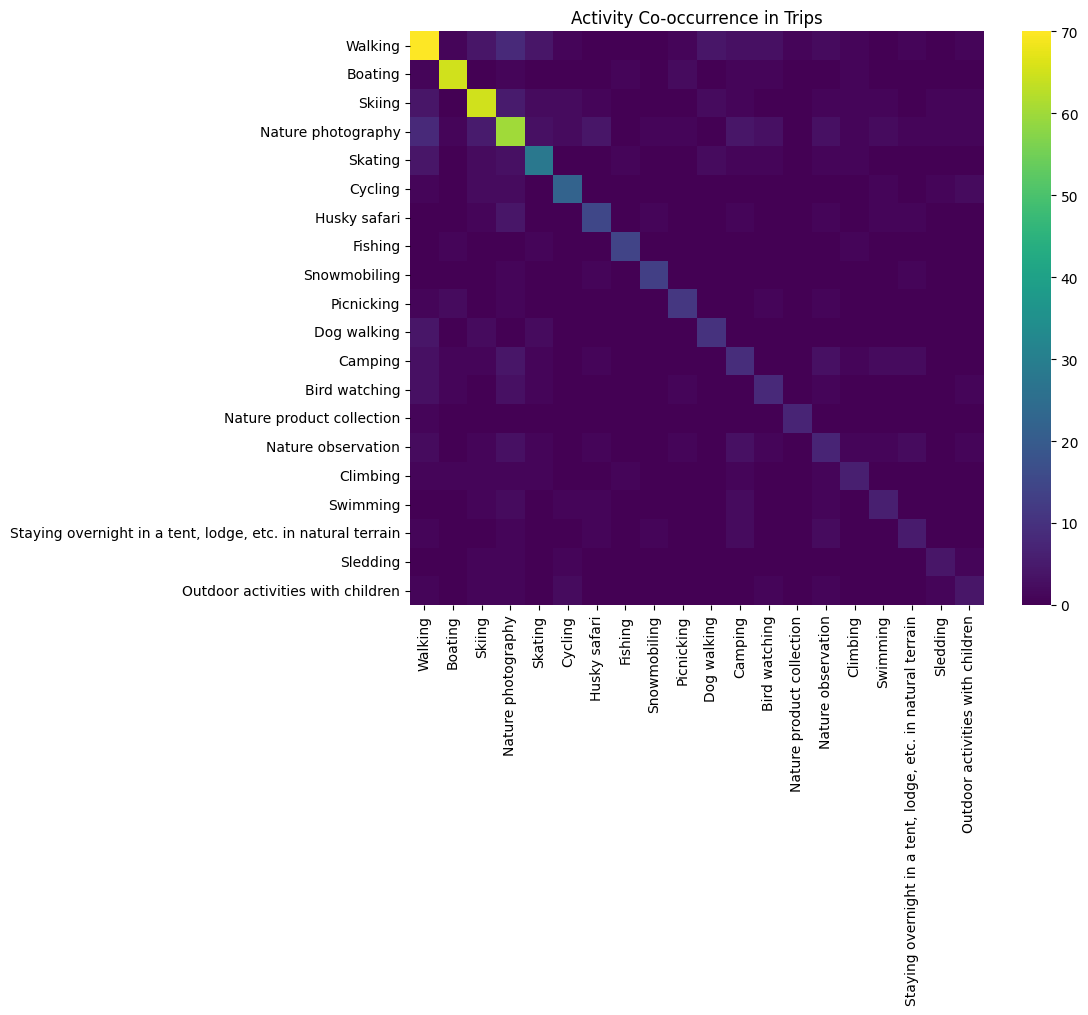

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: keep only top activities
top_activities = (
    activity_matrix.sum()
    .sort_values(ascending=False)
    .head(20)
    .index
)

co_matrix_top = co_matrix.loc[top_activities, top_activities]

plt.figure(figsize=(12, 10))

sns.heatmap(
    co_matrix_top,
    cmap='viridis',
    square=True
)

plt.title('Activity Co-occurrence in Trips')
plt.tight_layout()
plt.show()

In [64]:
from sklearn.metrics import jaccard_score

activities = activity_matrix.columns

jaccard_results = []

for i, a1 in enumerate(activities):
    for a2 in activities[i+1:]:

        score = jaccard_score(
            activity_matrix[a1],
            activity_matrix[a2]
        )

        jaccard_results.append({
            'activity_1': a1,
            'activity_2': a2,
            'jaccard': score
        })

df_jaccard = pd.DataFrame(jaccard_results)

df_jaccard.sort_values(by='jaccard', ascending=False)

,activity_1,activity_2,jaccard
111,Camping,Nature observation,0.230769
437,Nature observation,"Staying overnight in a tent, lodge, etc. in na...",0.200000
144,Climbing,Northern lights watching,0.166667
125,Camping,"Staying overnight in a tent, lodge, etc. in na...",0.166667
159,Climbing,Yoga,0.166667
...,...,...,...
219,Dog walking,Flying a kite,0.000000
218,Dog walking,Flying a drone,0.000000
217,Dog walking,Fishing,0.000000
216,Diving,Yoga,0.000000


## Trip temporal pattern

C:\Users\leyixu\AppData\Local\Temp\ipykernel_16056\832184775.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], data=gdf_flickr_trip, x='year', palette='viridis')
C:\Users\leyixu\AppData\Local\Temp\ipykernel_16056\832184775.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[1], data=gdf_flickr_trip, x='season', order=season_order, palette='coolwarm')
C:\Users\leyixu\AppData\Local\Temp\ipykernel_16056\832184775.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[2], data=gdf_flickr_trip, x='day_of_week',

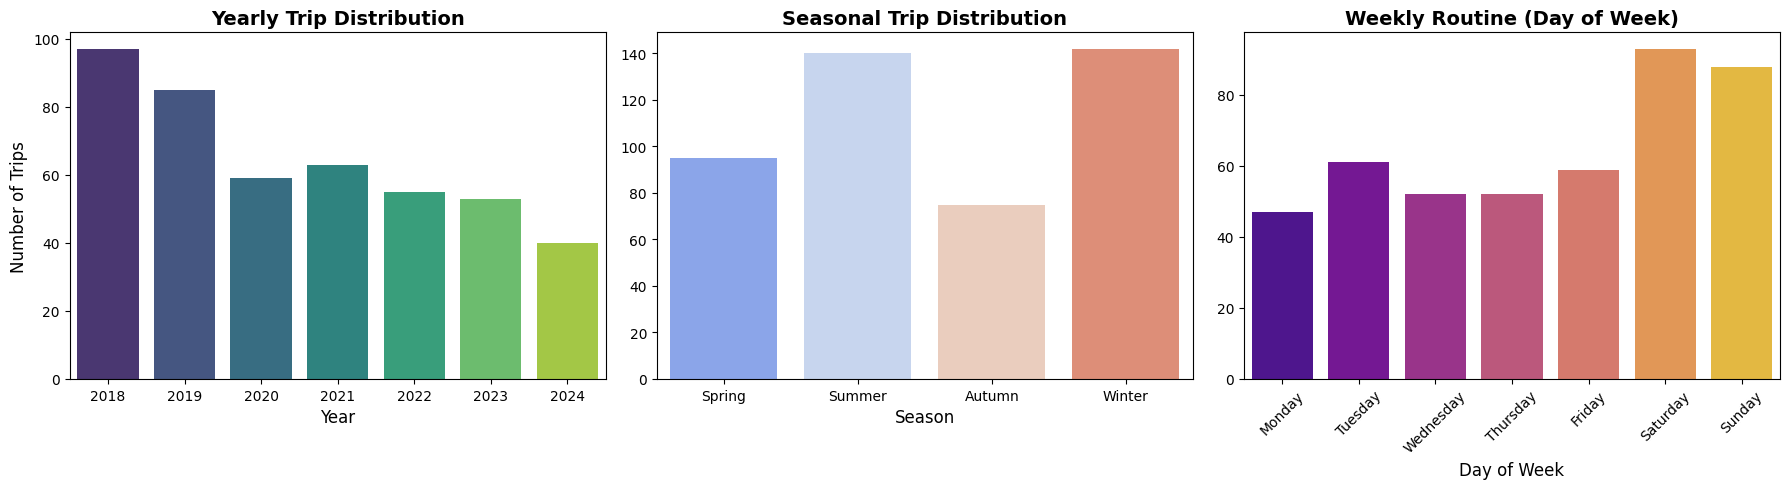

C:\Users\leyixu\AppData\Local\Temp\ipykernel_16056\832184775.py:69: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['trip_start'].dt.to_period('M').astype(str)


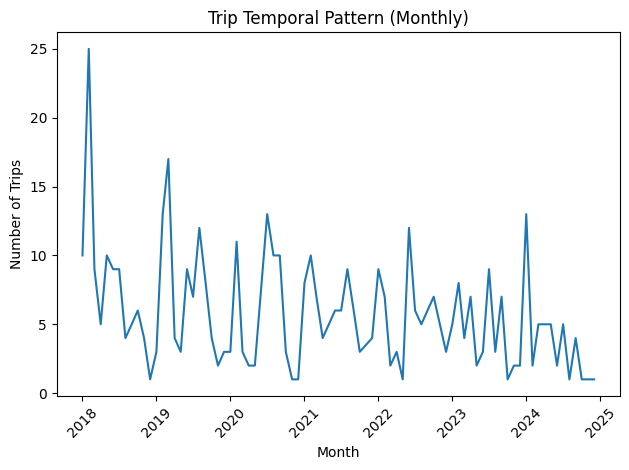

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure trip_start is parsed as a datetime object (handles timezones automatically)
gdf_flickr_trip['trip_start'] = pd.to_datetime(gdf_flickr_trip['trip_start'])

# 2. Extract Aggregated Temporal Features
gdf_flickr_trip['year'] = gdf_flickr_trip['trip_start'].dt.year
gdf_flickr_trip['month'] = gdf_flickr_trip['trip_start'].dt.month
gdf_flickr_trip['day_of_week'] = gdf_flickr_trip['trip_start'].dt.day_name()

# Define a function to map months to standard meteorological seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

gdf_flickr_trip['season'] = gdf_flickr_trip['month'].apply(get_season)

# Set logical chronological ordering for categorical plots
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']


# ==========================================
# DASHBOARD 1: Aggregated Cyclical Patterns
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: Yearly Distribution
sns.countplot(ax=axes[0], data=gdf_flickr_trip, x='year', palette='viridis')
axes[0].set_title('Yearly Trip Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Year', fontsize=12)
axes[0].set_ylabel('Number of Trips', fontsize=12)

# Plot B: Seasonal Distribution
sns.countplot(ax=axes[1], data=gdf_flickr_trip, x='season', order=season_order, palette='coolwarm')
axes[1].set_title('Seasonal Trip Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Season', fontsize=12)
axes[1].set_ylabel('')

# Plot C: Day of Week Distribution (Week-level Routine)
sns.countplot(ax=axes[2], data=gdf_flickr_trip, x='day_of_week', order=day_order, palette='plasma')
axes[2].set_title('Weekly Routine (Day of Week)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Day of Week', fontsize=12)
axes[2].set_ylabel('')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('trip_aggregated_patterns.png', dpi=300, bbox_inches='tight')
plt.show()


# ==========================================
# DASHBOARD 2: Continuous Weekly Timeline Trend
# ==========================================
# Group data by continuous year-week intervals
df = gdf_flickr_trip.copy()

df['trip_start'] = pd.to_datetime(df['trip_start'])

# Monthly temporal pattern
df['year_month'] = df['trip_start'].dt.to_period('M').astype(str)
ts = df.groupby('year_month').size().reset_index(name='trip_count')
ts['year_month'] = pd.to_datetime(ts['year_month'])
ts = ts.sort_values('year_month')

plt.figure()
plt.plot(ts['year_month'], ts['trip_count'])
plt.xticks(rotation=45)
plt.xlabel("Month")
plt.ylabel("Number of Trips")
plt.title("Trip Temporal Pattern (Monthly)")
plt.tight_layout()
plt.show()

## Spatial patterns

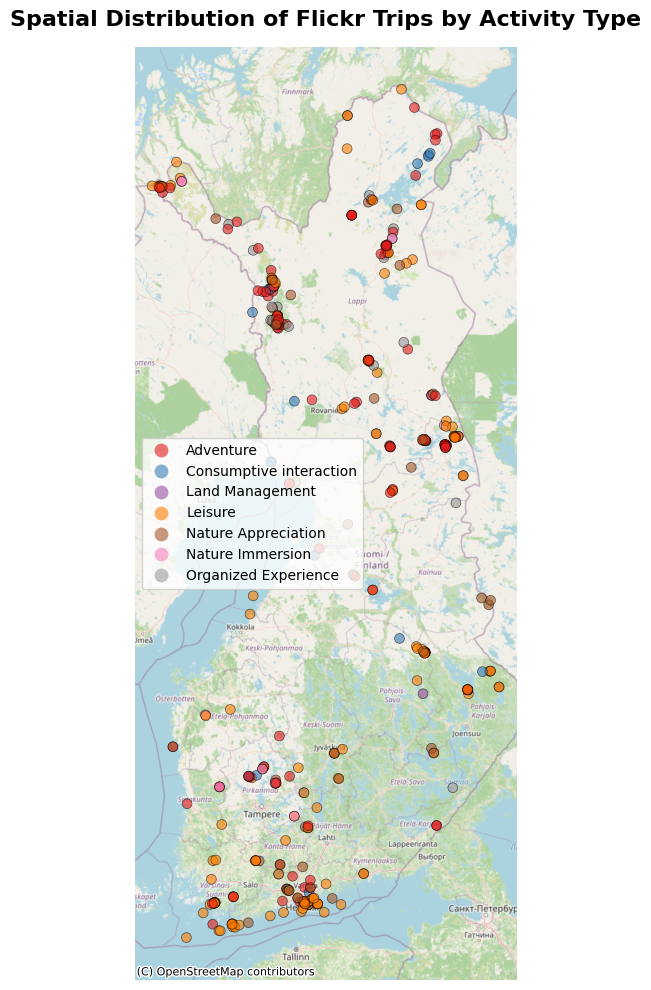

In [69]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

# 1. Double check / assign your current Coordinate Reference System (CRS) if not set.
# Looking at your sample data (e.g., POINT (361555.18 6690467.716)), this resembles ETRS89 / TM35FIN (EPSG:3067) often used in Finland.
# If it's already set, you can skip this if statement.
if gdf_flickr_trip.crs is None:
    # Replace 3067 with your actual EPSG code if different
    gdf_flickr_trip.set_crs(epsg=3067, inplace=True)

# 2. Contextily requires Web Mercator (EPSG:3857) to align points correctly with the basemap tiles
gdf_places_3857 = gdf_flickr_trip.to_crs(epsg=3857)

# 3. Plot the data
fig, ax = plt.subplots(figsize=(12, 10))

# Plot the trip points. We color code them by 'structural_activity' (e.g., Adventure vs Leisure)
# Alpha is set to 0.6 to see overlapping points easily.
gdf_places_3857.plot(
    ax=ax, 
    column='structural_activity', 
    categorical=True, 
    legend=True, 
    markersize=50, 
    cmap='Set1', 
    alpha=0.6, 
    edgecolor='k',
    linewidth=0.5
)

# 4. Add the basemap background
# Using OpenStreetMap Mapnik tiles. You can change this to ctx.providers.CartoDB.Positron for a gray background.
ctx.add_basemap(ax=ax, source=ctx.providers.OpenStreetMap.Mapnik)

# 5. Clean up the layout
ax.set_title('Spatial Distribution of Flickr Trips by Activity Type', fontsize=16, fontweight='bold', pad=15)
ax.set_axis_off() # Hide the Web Mercator axis coordinates for a cleaner look

plt.tight_layout()
plt.savefig('spatial_distribution_map.png', dpi=300, bbox_inches='tight')
plt.show()

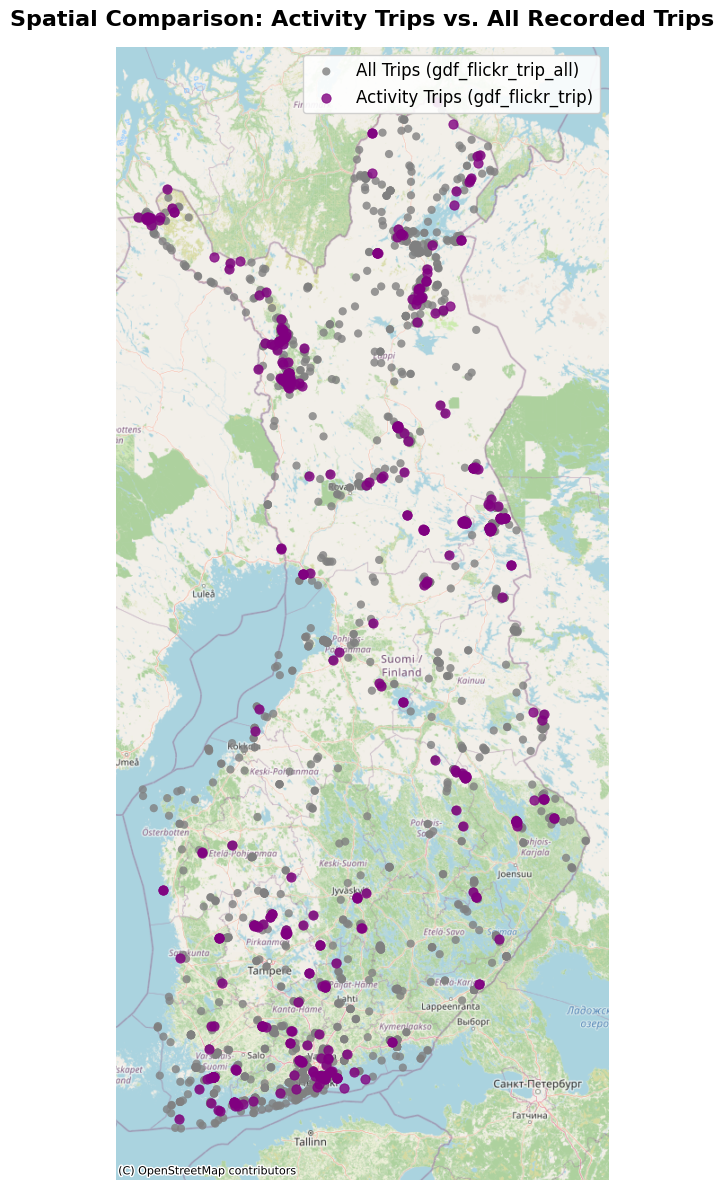

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

# 1. Handle Coordinate Reference System (CRS) matching
# Ensure both layers have their CRS declared before transforming
if gdf_flickr_trip.crs is None:
    gdf_flickr_trip.set_crs(epsg=3067, inplace=True) # Replace 3067 with your actual EPSG code

if gdf_flickr_trip_all.crs is None:
    gdf_flickr_trip_all.set_crs(epsg=3067, inplace=True)

# 2. Transform both layers to Web Mercator (EPSG:3857) for Contextily basemaps
gdf_trip_3857 = gdf_flickr_trip.to_crs(epsg=3857)
gdf_all_3857 = gdf_flickr_trip_all.to_crs(epsg=3857)

# 3. Initialize the plot
fig, ax = plt.subplots(figsize=(14, 12))

# 4. Plot Layer 1: All trips (Background / Grey)
gdf_all_3857.plot(
    ax=ax,
    color='grey',
    alpha=0.8,
    markersize=35,
    label='All Trips (gdf_flickr_trip_all)',
    edgecolor='none'
)

# 5. Plot Layer 2: Activity trips (Foreground / Purple)
gdf_trip_3857.plot(
    ax=ax,
    color='purple',
    alpha=0.8,
    markersize=45,
    label='Activity Trips (gdf_flickr_trip)',
    # edgecolor='black',
    linewidth=0.6
)

# 6. Add a clean, muted basemap so the colors stand out clearly
# CartoDB Positron is ideal here because it doesn't clash with your custom colors
ctx.add_basemap(ax=ax, source=ctx.providers.OpenStreetMap.Mapnik)

# 7. Map elements styling
ax.set_title('Spatial Comparison: Activity Trips vs. All Recorded Trips', fontsize=16, fontweight='bold', pad=15)
ax.set_axis_off()

# Force display of the legend matching our manual plot labels
plt.legend(loc='upper right', fontsize=12, frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.savefig('trip_layers_comparison_map.png', dpi=300, bbox_inches='tight')
plt.show()